In [86]:
%pip install torch
%pip install torch torchvision
%pip install numpy matplotlib scikit-learn
%pip install torch torchvision pandas pillow scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [87]:
# all the imports
import os
import re
import pandas as pd
import numpy as np

from PIL import Image
from torchvision import transforms
from torchvision.datasets import ImageFolder as ImageFolder
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier

Afmetingen aangepast Trainingset

In [88]:
class GefilterdeTumorDataset(Dataset):
    def __init__(self, root, min=256, transform=None): # min is minimale grens en root is hoofdmap
        # Haal de submappen op als klassen
        self.classes = [
            d for d in os.listdir(root)
            if os.path.isdir(os.path.join(root, d))
        ]

        self.images = []
        self.transform = transform

        for index, group in enumerate(self.classes):
            group_map = os.path.join(root, group)

            for filename in os.listdir(group_map):
                if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                    pad = os.path.join(group_map, filename)

                    # Controleer de afmetingen
                    with Image.open(pad) as img:
                        width, height = img.size

                    if width >= min and height >= min:
                        self.images.append((pad, index))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        pad, label = self.images[idx]
        img = Image.open(pad).convert('RGB')

        if self.transform:
            img = self.transform(img)

        return img, label


In [89]:
# Toepassing in jouw bestaande pipeline
transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

In [90]:
dataset_train = GefilterdeTumorDataset(root='./Training', min=256, transform=transform)
dataloader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)

print(f"Totaal aantal gefilterde foto's ingeladen: {len(dataset_train)}")

Totaal aantal gefilterde foto's ingeladen: 2559


In [91]:
dataset_test = GefilterdeTumorDataset(root='./Testing', min=256, transform=transform)
dataloader_test = DataLoader(dataset_test, batch_size=32, shuffle=True)

print(f"Totaal aantal gefilterde foto's ingeladen: {len(dataset_test)}")

Totaal aantal gefilterde foto's ingeladen: 212


In [92]:
csv_path = "./labeled_scans.csv"

df = pd.read_csv(csv_path)

# Bestandsnamen uit de image-kolom halen
df["filename"] = df["image"]
df["label"] = df["choice"]

label_mapping = {
    "Axiaal": 0,
    "Sagittaal": 1,
    "Coronaal": 2
}

# Alleen daadwerkelijk gelabelde afbeeldingen
df_labeled = df[df["label"].isin(label_mapping)].copy()

# Numerieke labels toevoegen
df_labeled["label_id"] = df_labeled["label"].map(label_mapping)

print("Aantal CSV-rijen:", len(df))
print("Aantal gelabelde CSV-rijen:", len(df_labeled))

print("\nVerdeling van de labels:")
print(df_labeled["label"].value_counts())

Aantal CSV-rijen: 159
Aantal gelabelde CSV-rijen: 159

Verdeling van de labels:
label
Coronaal     54
Sagittaal    53
Axiaal       52
Name: count, dtype: int64


In [109]:
# Handmatig gelabelde afbeeldingen koppelen aan labels
label_lookup = dict(
    zip(df_labeled["filename"], df_labeled["label_id"])
)

X = []
y = []
filenames = []

# Loop door ALLE afbeeldingen
for path, _ in dataset_train.images:

    filename = os.path.basename(path)

    # Bestaand label gebruiken, anders -1
    label = label_lookup.get(filename, -1)

    with Image.open(path) as img:
        img = img.convert("L").resize((64, 64))
        img_array = np.asarray(
            img, dtype=np.float32
        ).flatten() / 255.0

    X.append(img_array)
    y.append(label)
    filenames.append(filename)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=int)
filenames = np.array(filenames)

# Controle
print("Totaal aantal afbeeldingen:", len(X))
print("Aantal handmatig gelabeld:", np.sum(y != -1))
print("Aantal ongelabeld:", np.sum(y == -1))

print("\nVerdeling labels:")
print(np.unique(y, return_counts=True))

Totaal aantal afbeeldingen: 2559
Aantal handmatig gelabeld: 141
Aantal ongelabeld: 2418

Verdeling labels:
(array([-1,  0,  1,  2]), array([2418,   44,   50,   47]))


In [110]:
base_classifier = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    max_iter=10000,
    class_weight='balanced',
    l1_ratio=0.1,
    C=0.001
)

self_training_clf = SelfTrainingClassifier(
    base_classifier,
    criterion="k_best",
    k_best=2,
    max_iter=10
)

self_training_clf.fit(X, y)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

,"estimator estimator: estimator objectAn estimator object implementing `fit` and `predict_proba`.Invoking the `fit` method will fit a clone of the passed estimator,which will be stored in the `estimator_` attribute... versionadded:: 1.6 `estimator` was added to replace `base_estimator`.",LogisticRegre...solver='saga')
,"criterion criterion: {'threshold', 'k_best'}, default='threshold'The selection criterion used to select which labels to add to thetraining set. If `'threshold'`, pseudo-labels with predictionprobabilities above `threshold` are added to the dataset. If `'k_best'`,the `k_best` pseudo-labels with highest prediction probabilities areadded to the dataset. When using the 'threshold' criterion, a:ref:`well calibrated classifier <calibration>` should be used.",'k_best'
,"k_best k_best: int, default=10The amount of samples to add in each iteration. Only used when`criterion='k_best'`.",2
,"threshold threshold: float, default=0.75The decision threshold for use with `criterion='threshold'`.Should be in [0, 1). When using the `'threshold'` criterion, a:ref:`well calibrated classifier <calibration>` should be used.",0.75
,"max_iter max_iter: int or None, default=10Maximum number of iterations allowed. Should be greater than or equalto 0. If it is `None`, the classifier will continue to predict labelsuntil no new pseudo-labels are added, or all unlabeled samples havebeen labeled.",10
,"verbose verbose: bool, default=FalseEnable verbose output.",False
Name,Type,Value
"classes_ classes_: ndarray or list of ndarray of shape (n_classes,)Class labels for each output. (Taken from the trained`estimator_`).","ndarray[int64](3,)","[0,1,2]"
estimator_ estimator_: estimator objectThe fitted estimator.,LogisticRegression,LogisticRegre...solver='saga')
"labeled_iter_ labeled_iter_: ndarray of shape (n_samples,)The iteration in which each sample was labeled. When a sample hasiteration 0, the sample was already labeled in the original dataset.When a sample has iteration -1, the sample was not labeled in anyiteration.","ndarray[int64](2559,)","[ 1, 1, 2,...,-1,-1,-1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4096


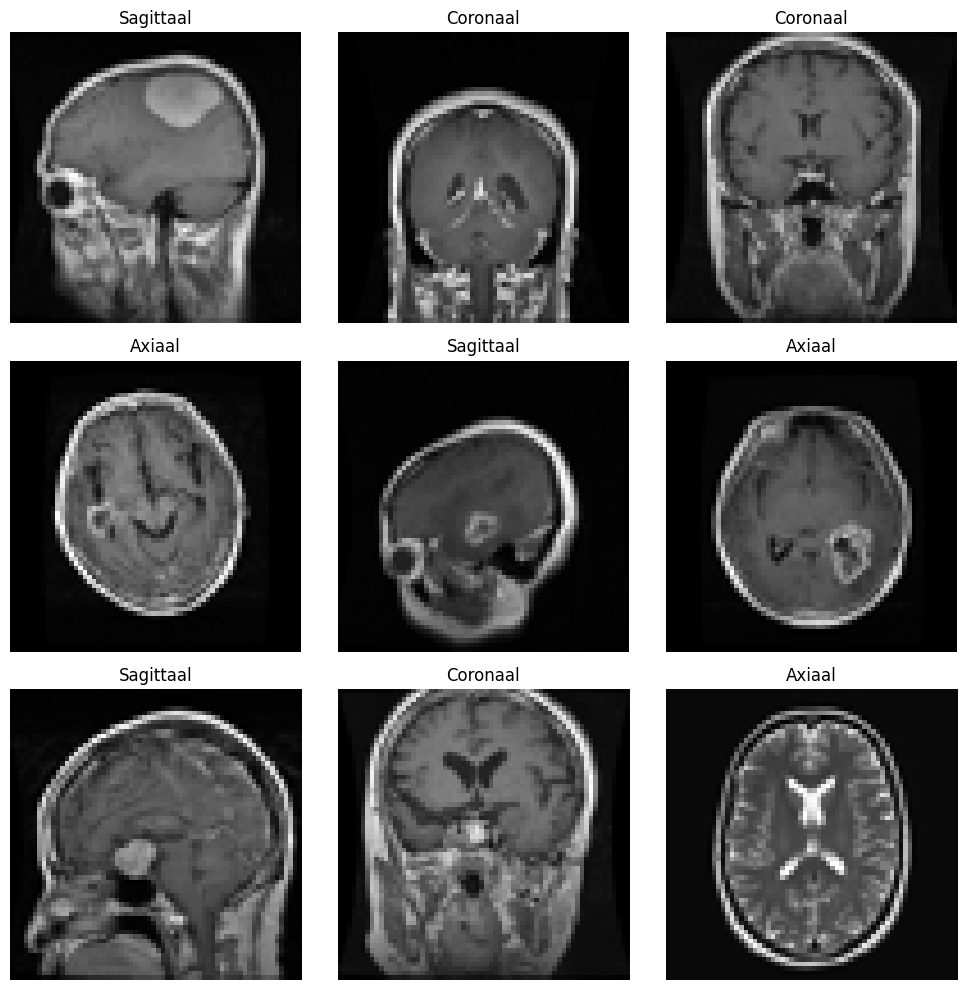

In [118]:
import matplotlib.pyplot as plt

# Alleen gelabelde afbeeldingen
labeled_indices = np.where(y != -1)[0]

label_names = {
    0: "Axiaal",
    1: "Sagittaal",
    2: "Coronaal"
}

# Toon 9 willekeurige gelabelde afbeeldingen
rng = np.random.default_rng(42)

selected = rng.choice(
    labeled_indices,
    size=min(9, len(labeled_indices)),
    replace=False
)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, idx in zip(axes.flat, selected):
    ax.imshow(X[idx].reshape(64, 64), cmap="gray")
    ax.set_title(label_names[y[idx]])
    ax.axis("off")

for ax in axes.flat[len(selected):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [114]:
import numpy as np
from sklearn.model_selection import train_test_split

# Alleen handmatig gelabelde afbeeldingen
mask_labeled = y != -1

X_labeled = X[mask_labeled]
y_labeled = y[mask_labeled]

# Ongelabelde afbeeldingen
X_unlabeled = X[y == -1]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_labeled,
    y_labeled,
    test_size=0.2,
    random_state=42,
    stratify=y_labeled
)

print("Gelabelde trainingsafbeeldingen:", len(X_train))
print("Testafbeeldingen:", len(X_test))
print("Ongelabelde afbeeldingen:", len(X_unlabeled))

Gelabelde trainingsafbeeldingen: 112
Testafbeeldingen: 29
Ongelabelde afbeeldingen: 2418


In [130]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Random Forest
base_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Trainen met handmatig gelabelde afbeeldingen
base_model.fit(X_train, y_train)

# Voorspellingen op testdata
y_pred = base_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["axiaal", "sagittaal", "coronaal"],
    zero_division=0
))

Accuracy: 0.896551724137931

Classification report:
              precision    recall  f1-score   support

      axiaal       0.89      0.89      0.89         9
   sagittaal       1.00      0.90      0.95        10
    coronaal       0.82      0.90      0.86        10

    accuracy                           0.90        29
   macro avg       0.90      0.90      0.90        29
weighted avg       0.90      0.90      0.90        29



In [128]:
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Combineer trainingsdata met ongelabelde afbeeldingen
X_semi = np.concatenate([X_train, X_unlabeled])

y_semi = np.concatenate([
    y_train,
    np.full(len(X_unlabeled), -1)
])

# Random Forest
semi_base_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Self-training
self_training_clf = SelfTrainingClassifier(
    estimator=semi_base_model,
    threshold=0.90,
    max_iter=20
)

# Trainen
self_training_clf.fit(X_semi, y_semi)

# Resultaten
nieuwe_labels = np.sum(
    (y_semi == -1) &
    (self_training_clf.transduction_ != -1)
)

print("Aantal nieuwe pseudo-labels:", nieuwe_labels)
print("Aantal iteraties:", self_training_clf.n_iter_)
print("Stopreden:", self_training_clf.termination_condition_)

Aantal nieuwe pseudo-labels: 2128
Aantal iteraties: 20
Stopreden: max_iter


In [127]:
from sklearn.metrics import accuracy_score, classification_report

# Voorspellingen op dezelfde testset
y_pred_base = base_model.predict(X_test)
y_pred_semi = self_training_clf.predict(X_test)

print("Random Forest accuracy:",
      accuracy_score(y_test, y_pred_base))

print("Self-training accuracy:",
      accuracy_score(y_test, y_pred_semi))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_semi,
    labels=[0, 1, 2],
    target_names=["axiaal", "sagittaal", "coronaal"],
    zero_division=0
))

Random Forest accuracy: 0.896551724137931
Self-training accuracy: 0.8275862068965517

Classification report:
              precision    recall  f1-score   support

      axiaal       0.73      0.89      0.80         9
   sagittaal       0.90      0.90      0.90        10
    coronaal       0.88      0.70      0.78        10

    accuracy                           0.83        29
   macro avg       0.83      0.83      0.83        29
weighted avg       0.84      0.83      0.83        29



In [131]:
import pandas as pd
import numpy as np

# Alleen de oorspronkelijk ongelabelde afbeeldingen
mask_unlabeled = y == -1

X_unlabeled = X[mask_unlabeled]
filenames_unlabeled = filenames[mask_unlabeled]

# Voorspellingen maken
y_pred = self_training_clf.predict(X_unlabeled)

# Numerieke labels omzetten naar aanzichten
label_names = {
    0: "axiaal",
    1: "sagittaal",
    2: "coronaal"
}

# CSV maken
results = pd.DataFrame({
    "image": filenames_unlabeled,
    "voorspeld_aanzicht": [
        label_names[label] for label in y_pred
    ]
})

# Opslaan
results.to_csv("voorspelde_aanzichten.csv", index=False)